# 🔍 11-03 · 时间序列分解：趋势 / 季节 / 残差各归其位

> 目标：把序列拆成可解释的三块。学完本篇你能——
> ① 手写**中心化移动平均去趋势 + 季节指数**，完成「分解 → 残差诊断 → 评价分解质量」的经典流程；
> ② 讲清**为什么偶数周期要两步平均**，并手算 m=4 小段验证；
> ③ 实现**乘法分解**（季节指数是比例）并说出何时用对数转加法；
> ④ 理解 **STL 算法**（内循环/外循环/鲁棒权重），用简化版迭代与 statsmodels 对照；
> ⑤ 计算**季节强度 F_s**、跑**分解驱动预测工作流**（去季节建模 → 叠回季节 → 留出评估）。

> 📍 **主线位置**：前一篇 02 篇（指数平滑，状态递推预测）→ 本篇《时间序列分解》（**结构拆解 + 可解释性**）→ 后一篇 04 篇（特征工程与机器学习，把"手工结构"换成"自动特征 + 模型"）。
> 本篇是"看清数据长什么样"的放大镜：EDA 报告、季节性调整、异常检测基线都靠它。

> 🧩 **生活化类比**：分解 = 把"一年销售曲线"拆成三张图——长期走势（趋势）、每年固定节奏（季节）、以及"说不清道不明"的部分（残差）。残差越小，模型越完整。

## 核心概念

### (a) 🗂️ 把序列拆成三张图：时间序列分解

把一年销售曲线拆成长期走势（趋势）、每年固定节奏（季节）和说不清的残差三块。本篇手写「中心化移动平均去趋势 + 季节指数」的经典分解，用残差方差占比和 Ljung-Box 评价分解质量，再讲 STL 这个现代升级版。

```mermaid
flowchart TB
    Node1["➕ 加法 vs 乘法模型"]
    Node2["🔄 中心化移动平均去趋势"]
    Node3["🗓️ 季节指数"]
    Node4["🧹 残差"]
    Node5["📊 分解质量量化"]
    Node6["🔬 STL：现代分解"]
    Node1 --> Node2
    Node2 --> Node3
    Node3 --> Node4
    Node4 --> Node5
    Node1 --> Node6
    Node6 -->|更鲁棒| Node5
```

### (b) 六个必须带走的概念（上）

- **加法 vs 乘法模型**：加法 $y_t = T + S + R$，季节幅度不随水平变化；乘法 $y_t = T \\times S \\times R$，季节幅度随水平缩放（销售额越高波动越大）。对数变换可以把乘法变加法：$\\log y = \\log T + \\log S + \\log R$。
- **中心化移动平均去趋势**：用移动平均把趋势 T 提出来。偶数周期（如月度 m=12）要「先 m 期平均再 2 期平均」两步对齐时间点。
- **季节指数**：原序列减去趋势后，按周期位置（1 月、2 月……）取均值，得到每个位置的「季节偏差」——某个位置显著偏离 0，说明确有季节效应。

### (c) 六个必须带走的概念（下）

- **残差**：原序列 − 趋势 − 季节 = 残差 R，是「说不清道不明」的随机部分。理想残差应该是白噪声。
- **分解质量量化**：残差方差占比 Var(R)/Var(y) 越小，分解解释力越强；再用 Ljung-Box 检验残差——通过（p 大）说明无残留结构。
- **STL 现代分解**：用 LOESS 局部回归迭代估计趋势与季节，内循环外循环交替平滑。比经典分解强在：季节形状可随时间缓慢变化、对异常点鲁棒（外循环降权）、可加性框架任意周期。

## 0. 主线地图

```
原始序列 y
   │
   ▼
① 选模型：加法 or 乘法（看季节振幅随不随水平变）
   │
   ▼
② 移动平均提取趋势 T（偶数周期两步平均）
   │
   ▼
③ 去趋势 → 按周期位置均值得季节 S
   │
   ▼
④ 残差 R = y - T - S；残差方差占比 + Ljung-Box 诊断
   │
   ▼
⑤ 不干净 → 换 STL（LOESS 迭代 + 鲁棒）；干净 → 去季节建模
```

### 0.1 历史背景：从移动平均到 STL

- **1910s-1950s（移动平均年代）**：统计学家用固定窗口移动平均提取趋势。1920s 的 **X-11**（美国普查局）把移动平均 + 季节因子做成了工业化流程，后升级为 **X-13-ARIMA-SEATS**（含 ARIMA 预测外延与模型化季节调整）。
- **1990 年 Cleveland et al. 提出 STL**：Seasonal-Trend decomposition using **LOESS**——用局部回归迭代同时估计趋势与季节，允许季节形状**缓慢漂移**、对异常点**鲁棒**，成为 Python/R 的默认分解工具。
- **一句话谱系**：移动平均（可手算）→ X-13（普查局工业化）→ STL（统计鲁棒迭代）；本篇手写第一条，用 statsmodels 对照第三条。
- **一句话记忆**：**先减趋势、再按月份取均值、剩下的就是残差**——经典三步，STL 只是把"均值/平均"换成"局部回归 + 迭代"。

### 0.2 为什么需要分解？三个典型用途

1. **EDA 报告**：一张 4 联图（y / T / S / R）就能说清"长期走势 + 季节节奏 + 随机波动"。
2. **季节性调整**：经济数据（CPI、零售）发布"经季调"版本——先把季节分量去掉再比较环比。
3. **异常检测基线**：残差 R 的 z-score 找异常（06 篇做完整版）；对原序列找异常会被季节"带偏"。

> 面试一句话：**分解把"看得懂的部分（T、S）"和"看不懂的部分（R）"分开**——解释、调整、检测全靠它。

## 1. 加法与乘法模型：完整对照

| | 加法 $y_t = T_t + S_t + R_t$ | 乘法 $y_t = T_t \\times S_t \\times R_t$ |
|---|---|---|
| 季节振幅 | 固定，不随水平变化 | 随水平缩放（越高波动越大） |
| 适用 | 温度、心率、稳定业务量 | 零售额、GMV、流量（水平上升波动放大） |
| 残差含义 | R 是绝对量（±） | R 是比例（1±几分） |
| 处理技巧 | 直接分解 | 取对数转加法：$\\ln y = \\ln T + \\ln S + \\ln R$ |
| 季节指数 | 偏差（可正可负） | 比例（>0，围绕 1 波动） |

**怎么选**：画图看**峰谷差是否随水平走**——峰谷差放大 → 乘法（或对数）；峰谷差稳定 → 加法。

### 1.1 经典分解三步

**经典分解三步**：① 移动平均提取趋势 $T$；② 去趋势后按周期均值得季节 $S$；③ 残差 $R = y - T - S$。

> 面试一句话：**"减趋势、按位置取均值、剩下是残差"——三步走完，序列就被拆成了可解释的三块**。

## 2. 中心化移动平均：为什么偶数周期要两步？(重点)

对长度 $m$ 的窗口取平均，$\\hat T_t = \\frac{1}{m}\\sum_{j=-k}^{k} y_{t+j}$ 只有当 $m$ 为**奇数**时窗口关于 $t$ 对称（$m=2k+1$）。

**偶数周期（如 m=24）的困局**：窗口 $t-12, \\ldots, t+11$ 关于 $t$ 不对称——平均值落在 $t-0.5$ 上，而不是 $t$ 上。

**两步平均解决**：
1. 第一步：$m$ 期平均 → 指标落在半整数点 $t-0.5$；
2. 第二步：相邻两个"半步均值"再平均 → 指标回到整数点 $t$。

$$\\hat T_t = \\frac{1}{2}\\Big( \\frac{1}{m}\\sum_{j=-m/2+1}^{m/2} y_{t+j-1} + \\frac{1}{m}\\sum_{j=-m/2}^{m/2-1} y_{t+j} \\Big)$$

> 面试一句话：**偶数窗口均值落在点半格，再做一次 2 期平均把它"搬回"整数格**——这就是中心化。

### 2.1 手算 m=4 小段

设 $y = [1, 3, 5, 7, 9, 11]$（线性增长，每步+2）。

第一步（4 期平均，落在半点）：$\\bar y_{1.5} = (1+3+5+7)/4 = 4$，$\\bar y_{2.5} = (3+5+7+9)/4 = 6$，$\\bar y_{3.5} = (5+7+9+11)/4 = 8$。

第二步（2 期平均，搬回整数）：$\\hat T_2 = (4+6)/2 = 5$，$\\hat T_3 = (6+8)/2 = 7$。

> 验证：线性序列 $y_2=3,\\ y_3=5,\\ y_4=7$——中心化 MA 输出 $5, 7$ 正好落在 $y_3, y_4$ 附近的线性延展上，**无相位偏移**。

## 3. 季节指数：去趋势后按周期位置取均值

**步骤**：
1. 去趋势：$d_t = y_t - \\hat T_t$（加法模型）；
2. 按周期位置分组：第 $p$ 个位置取所有 $d_p,\\ d_{p+m},\\ d_{p+2m},\\ldots$ 的均值；
3. 得 $\\hat S_p$（$p=1..m$），周期外推得到 $\\hat S_t$。

**为什么避开 MA 边界**：卷积 `mode='same'` 在首尾约 $m/2$ 个点不完整，趋势估计偏差大 → 季节指数只用中段样本。

**手算小例（m=4, 两周期）**：设去趋势序列 $d = [0.5,\\ -1.2,\\ 1.8,\\ -0.4,\\ 0.7,\\ -1.0,\\ 2.0,\\ -0.6]$。

| 位置 p | 样本 | 均值 $\\hat S_p$ |
|---|---|---|
| 1 | 0.5, 0.7 | 0.6 |
| 2 | -1.2, -1.0 | -1.1 |
| 3 | 1.8, 2.0 | 1.9 |
| 4 | -0.4, -0.6 | -0.5 |

> 位置 3 的指数 1.9 显著为正 → 该周期位置系统性地高于趋势。

## 4. 分解质量：残差方差占比 + Ljung-Box + 季节强度

**残差占比**：$\\text{share} = \\dfrac{\\text{Var}(R)}{\\text{Var}(y)}$——占比越小，趋势+季节解释力越强。

**Ljung-Box**（00 篇）：$Q = n(n+2)\\sum_{k=1}^{h}\\dfrac{\\hat\\rho_k^2}{n-k}$；p>0.05 → 残差无残留自相关。

**季节强度 $F_s$**：
$$F_s = \\max\\left(0,\\ 1 - \\frac{\\text{Var}(R)}{\\text{Var}(S+R)}\\right)$$

- $F_s \\to 1$：季节性强（残差占比小，季节主导）；
- $F_s \\to 0$：几乎没有季节（残差占比接近 1，季节与残差难以区分）。

> 面试一句话：**分解质量 = 残差越小越好 + 残差像白噪声**；$F_s$ 把"季节解释了多少"压成一个 0-1 的指标。

### 4.1 正态性简述（Shapiro）

分解残差除了"无自相关"，还常看**正态性**：Shapiro-Wilk 检验 $H_0$：样本来自正态分布，p<0.05 拒绝。

- 正态残差 → z-score 类异常检测、参数化预测区间（±1.96σ）成立；
- 残差异常偏斜/重尾 → 考虑对数变换（乘法结构）或鲁棒统计量（中位数/MAD）。

> 面试一句话：**Ljung-Box 查"相关残留"，Shapiro 查"分布假设"**——两个都过，残差才是真白噪声。

## 5. 乘法分解：季节指数变成"比例"

乘法模型 $y_t = T_t \\times S_t \\times R_t$。**关键差异**：$\\hat S_p$ 不再是"偏差"而是"比例"（围绕 1 波动，可乘回），残差是比值。

**乘法实现**：
1. 趋势：仍用中心化 MA（对原始 $y$）；
2. 去趋势（除法）：$d_t = y_t / \\hat T_t$（$y>0$ 必须满足）；
3. 季节比例：按周期位置取 $d_t$ 的**均值**（或中位数更鲁棒），$\\hat S_p$ 于是围绕 1；
4. 残差：$R_t = y_t / (\\hat T_t \\cdot \\hat S_t)$。

### 5.1 为什么要求 y>0 + 对数捷径

**为什么要求 $y>0$**：除法遇到 0 或负数无意义；实际业务（GMV、流量）通常为正，若不正则先加常数或考虑其他模型。

**对数捷径**：$\\ln y_t = \\ln T_t + \\ln S_t + \\ln R_t$——把乘法分解转成加法分解，直接复用加法流程。

> 面试一句话：**加法减趋势、乘法除趋势；加法季节是偏差、乘法季节是比例**——对数变换可把乘法变加法统一处理。

## 6. STL 算法：LOESS 迭代 + 鲁棒（现代默认）

**STL（Seasonal-Trend decomposition using LOESS）**，Cleveland 1990：

**内循环**（迭代估计季节与趋势）：
1. **去趋势**：从原序列减去当前趋势估计，得到"季节+残差"；
2. **季节子序列平滑**：把每个周期位置（1 月、2 月……）的序列分别用 LOESS 平滑（得到季节分量）；
3. **低通滤波**：对季节分量做移动平均（再平滑），把季节分量调整到慢变；
4. **去季节**：原序列减去第 2 步季节；
5. **趋势平滑**：对去季节序列再做 LOESS（或 MA 近似）得新趋势。

### 6.1 外循环 + 简化伪代码

**外循环（鲁棒）**：计算残差，用残差大小给每点加权（残差大的点权重小），下一轮内循环用加权 LOESS——**对异常点鲁棒**。

**简化实现**（教学用 moving average 近似 LOESS）：

```
for outer in range(2):                      # 外循环：鲁棒
    for inner in range(2):                  # 内循环：交替平滑
        trend = centered_ma(y - season, m)  # 5. 趋势
        det = y - trend                     # 1. 去趋势
        season = per_position_ma(det, m, w) # 2. 周期位置平滑
    w = robust_weight(y - trend - season)   # 外循环权重
```

> 面试一句话：**STL = 交替做"去趋势→季节平滑→去季节→趋势平滑"，外层按残差降权**——比移动平均均值更鲁棒、季节还可漂移。

### 6.1 与经典分解的对比

| | 经典（MA + 均值） | STL（LOESS 迭代） |
|---|---|---|
| 季节形状 | 固定（一个周期的均值） | 可随**时间缓慢漂移** |
| 异常点 | 拖累均值 | 外循环降权，鲁棒 |
| 周期 | 需整除 | 任意整数 |
| 实现难度 | 手写 10 行 | 调用 statsmodels |

> 面试一句话：**STL 是经典分解的"鲁棒 + 可漂移"升级版**。

## 7. STL 的杀手锏：季节形状随时间漂移

经典分解假设季节形状固定；STL 允许逐个周期位置做平滑，**季节相位/幅度可缓慢变化**。

在"季节幅度从 3 慢慢涨到 8"的数据上：
- 经典分解：用整段均值 → 高估早期、低估后期；
- STL：逐位置平滑 → 幅度变化被跟上。

> 面试一句话：**数据里季节在变 → 用 STL；季节稳定 → 经典分解也够**。

### 7.1 异常检测基线：残差比原序列好使

分解的经典落地：**在残差 R 上做 z-score**（06 篇做完整版）。

- 原序列 z-score：季节峰的"正常高值"被误判异常；
- 残差 z-score：季节与趋势已剥离，只有真异常突出。

> 面试一句话：**找异常要在残差里找，别在原序列里找——否则每个夏天都是"异常"**。

## 8. 分解驱动预测：去季节建模 → 叠回季节

工业界常用工作流（比直接对原始序列建模更稳）：
1. **分解**：得到 $T$（含趋势）与 $S$（季节）；
2. **去季节**：$y^{\\text{ds}}_t = y_t - S_t$（只剩趋势+残差）；
3. **对去季节序列建模**：AR / 指数平滑 / 线性趋势都可（趋势部分好建模）；
4. **预测 + 叠回季节**：$\\hat y_{t+h} = \\hat y^{\\text{ds}}_{t+h} + \\hat S_{t+h}$；
5. **留出集评估**：对比"分解工作流" vs "直接对原序列建模"。

### 8.1 为什么"去季节再建模"更稳？

- **直接对原序列建模**：模型要用有限参数同时拟合趋势 + 季节 + 噪声，季节这种"锯齿状"结构对 AR 类模型是负担（要很多阶数或季节项）。
- **分解工作流**：季节被显式分离，模型只需拟合平滑的趋势残差——**结构分而治之**。
- **业务理解**：能分别回答"趋势涨多少"与"这个月比平常高多少"。

> 面试一句话：**把已知结构（季节）拆出去，模型只学残差里的规律——分而治之，更稳更可解释**。

## 数字敏感度与易错点

1. **偶数周期必须两步平均**：忘记中心化 → 趋势有半格相位偏移，季节/残差被污染。
2. **MA 边界不可靠**：`mode='same'` 首尾约 $m/2$ 个点是"补零"卷积产物，季节指数和残差统计要裁剪边界。
3. **乘法分解要求 $y>0$**：出现 0/负值会毁掉除法；对数变换同样要求正值。
4. **加法/乘法选错**：峰谷差随水平放大却用加法 → 残差有"喇叭形"结构，Ljung-Box 过不了。
5. **季节周期 m 是已知/先验**：分解不自证 m；用错 m（如 12 vs 13）会把季节踢进残差。
6. **STL 参数**：`period`、`seasonal`（季节平滑窗口）、`robust`（是否外循环）影响结果；一般保持默认调 period。
7. **F_s 接近 0**：不是"分解失败"，是"本来就没季节"——此时季节强度指标本身就是结论。
8. **泄漏**：分解用的趋势/季节必须只用训练段估计（实验 8 已示范），否则预测虚高。

### 一句话总结本篇

```
y = T + S + R（加法）或 y = T × S × R（乘法）
     │
     ▼
经典：中心化 MA 去趋势 → 周期均值季节 → 残差诊断
     ▼
升级：STL 迭代（LOESS + 鲁棒）→ 季节可漂移
     ▼
落地：去季节建模 → 叠回季节 → 留出评估
```

**四件必须带走的事**：① 偶数周期中心化两步平均；② 乘法=比例季节、要求 y>0；③ 分解质量看残差方差占比 + Ljung-Box + F_s；④ 预测工作流先拆季节再建模。

## 面试速答（30 秒背诵版）

- **加法 vs 乘法**：季节幅度是否随水平变化；对数把乘法变加法
- **经典三步**：MA 去趋势 → 周期均值季节指数 → 残差
- **中心化 MA**：偶数周期需两步平均对齐时间点（4 期→半点→整数点）
- **乘法分解**：除趋势 + 比例季节（围绕 1）；要求 y>0
- **季节强度**：$F_s = \\max(0, 1 - \\text{Var}(R)/\\text{Var}(S+R))$，→1 季节性强
- **STL**：LOESS 迭代、季节可漂移、外循环鲁棒；经典 = MA + 均值
- **分解预测工作流**：去季节建模 → 叠回季节 → 留出评估
- **残差诊断**：Ljung-Box + 方差占比；残差不白噪声 → 结构没提干净

## 自测清单

- [ ] 手写中心化移动平均（偶数周期两步平均）并说出为什么
- [ ] 手算 m=4 线性序列 y=[1,3,5,7,9,11] 的中心化 MA（得 5,7）
- [ ] 手写季节指数（去趋势后周期位置均值）
- [ ] 手算 m=4 季节指数小例（d=[0.5,-1.2,1.8,-0.4,...] → [0.6,-1.1,1.9,-0.5]）
- [ ] 手写乘法分解并说出与加法的三个差异
- [ ] 计算残差方差占比 + 季节强度 F_s 并解释含义
- [ ] 说清 STL 与经典分解的三个差异（漂移/鲁棒/任意周期）
- [ ] 说清 STL 内循环的五个小步骤
- [ ] 跑分解驱动预测工作流并解释为什么更准
- [ ] 口算：为什么乘法数据用加法分解残差占比会偏大
- [ ] 说出分解的三个应用场景（EDA/季节调整/异常基线）

> 💡 下一篇 `04-特征工程与机器学习`：把"手工结构"换成"自动特征 + 模型"——滞后/滚动统计/时间编码 + HistGradientBoosting + purged CV。

## 延伸阅读与知识图谱

```text
   原始序列 y
     ├─ 经典分解：MA 去趋势 + 周期均值季节 + 残差
     │     ├─ 加法（振幅稳定） / 乘法（振幅缩放）
     │     └─ 残差诊断：Ljung-Box + 方差占比 + F_s
     └─ STL：LOESS 迭代（内循环 5 步 + 外循环鲁棒）
           ├─ 季节可漂移 / 鲁棒 / 任意周期
           └─ 分解驱动预测：去季节建模 → 叠回季节
   下一篇 04-特征工程与机器学习：滑窗监督学习 / HGB / purged CV
```

- **延伸阅读**：Cleveland et al. (1990) *J. Official Statistics*（STL 原始论文）；Hyndman & Athanasopoulos *Forecasting* 第 3、6 章（分解与 STL）；美国普查局 X-13ARIMA-SEATS 文档（工业化季节调整）。

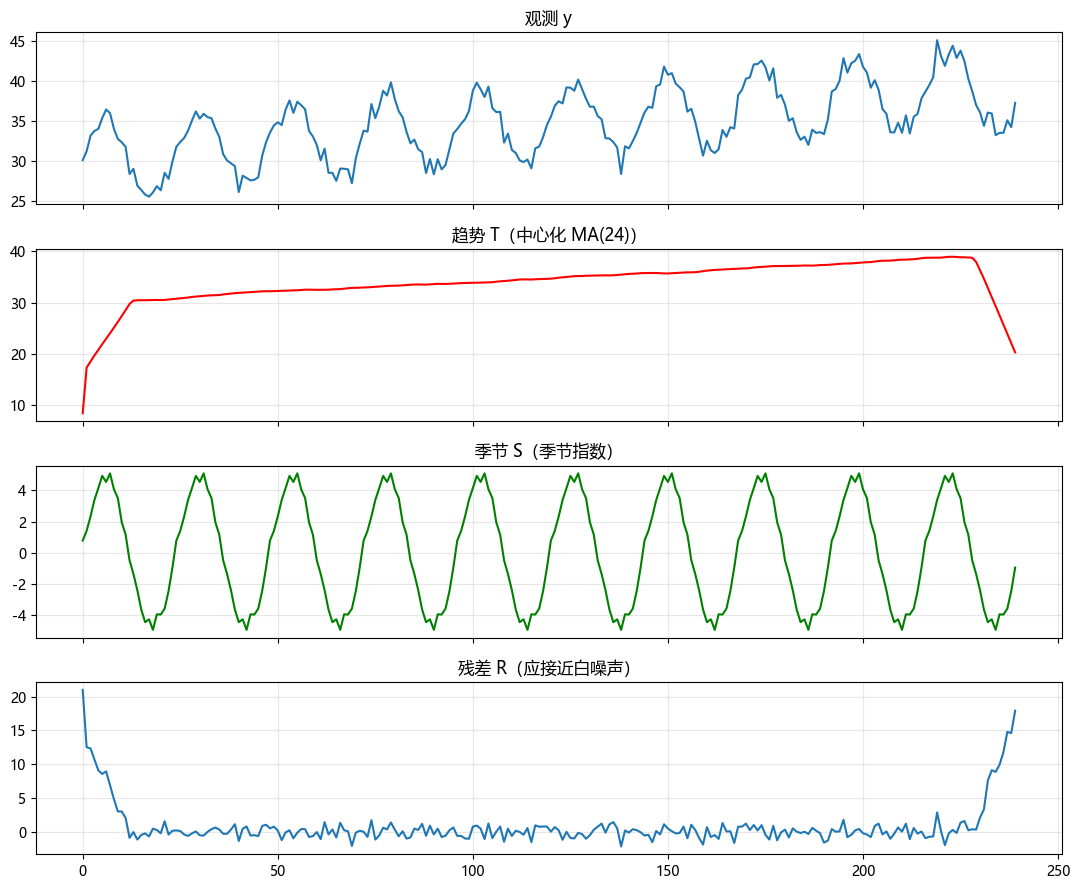

残差标准差(裁剪边界)=0.805（噪声真值 0.9）| 季节幅度估计=10.016（真值 10）
要点：残差≈白噪声 + 季节幅度≈2×振幅，说明分解把结构"提"干净了


In [1]:
# ---------- 实验 1：手写经典分解（中心化移动平均 + 季节指数） ----------
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
rng = np.random.default_rng(0)

n = 240; m = 24                                    # 24 个季节周期
t = np.arange(n)
y = 30 + 0.04 * t + 5 * np.sin(2 * np.pi * t / m) + rng.normal(0, 0.9, n)

def centered_ma(x, m):
    # 偶数周期用两步平均（中心化）：先 m 期平均再 2 期平均
    pad = m // 2
    c = np.convolve(x, np.ones(m) / m, mode='same')
    c = np.convolve(c, np.ones(2) / 2, mode='same') if m % 2 == 0 else c
    return c

trend = centered_ma(y, m)
detrend = y - trend
# 季节指数只用 MA 边界效应区之外的样本（'same' 卷积首尾约 m/2 个点不可靠）
season = np.zeros(m); cnt = np.zeros(m)
for i in range(m // 2, n - m // 2):
    season[i % m] += detrend[i]; cnt[i % m] += 1
season /= cnt
season_full = np.tile(season, n // m + 1)[:n]
resid = y - trend - season_full

fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
axes[0].plot(y); axes[0].set_title('观测 y')
axes[1].plot(trend, 'r'); axes[1].set_title('趋势 T（中心化 MA(24)）')
axes[2].plot(season_full, 'g'); axes[2].set_title('季节 S（季节指数）')
axes[3].plot(resid); axes[3].set_title('残差 R（应接近白噪声）')
for a in axes: a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('images/ts03_decomp.png', dpi=110, bbox_inches='tight'); plt.show()

print('残差标准差(裁剪边界)=%.3f（噪声真值 0.9）| 季节幅度估计=%.3f（真值 10）' %
      (resid[12:-12].std(), season.max() - season.min()))
assert resid[12:-12].std() < 1.5 and abs((season.max() - season.min()) - 10) < 2
print('要点：残差≈白噪声 + 季节幅度≈2×振幅，说明分解把结构"提"干净了')

In [2]:
# ---------- 实验 2：米=4 手算小例 + numpy 复算 ----------
y4 = np.array([1, 3, 5, 7, 9, 11], dtype=float)

# 两步法 numpy
c1 = np.convolve(y4, np.ones(4) / 4, mode='valid')     # 落在半点
c2 = np.convolve(c1, np.ones(2) / 2, mode='valid')     # 搬回整数
print('4 期平均(半点):', np.round(c1, 3))
print('再 2 期平均(整数):', np.round(c2, 3))
assert np.allclose(c2, [5.0, 7.0]), '手算 m=4 中心化应得 5, 7'

# 与中心化无偏对应：线性序列上 3 期对称平均对照
c3 = np.convolve(y4, np.ones(3) / 3, mode='valid')
print('3 期对称平均:', np.round(c3, 3), '（奇数窗口不需要第二步）')
print('✅ m=4 两步平均 = 对齐时间点；奇数窗口天然对称')

4 期平均(半点): [4. 6. 8.]
再 2 期平均(整数): [5. 7.]
3 期对称平均: [3. 5. 7. 9.] （奇数窗口不需要第二步）
✅ m=4 两步平均 = 对齐时间点；奇数窗口天然对称


In [3]:
# ---------- 实验 3：手算 m=4 季节指数 + numpy 复算 ----------
d4 = np.array([0.5, -1.2, 1.8, -0.4, 0.7, -1.0, 2.0, -0.6])
m4 = 4
season_hand = np.zeros(4); cnt = np.zeros(4)
for i in range(len(d4)):
    season_hand[i % m4] += d4[i]; cnt[i % m4] += 1
season_hand /= cnt
print('手算季节指数:', np.round(season_hand, 3))
assert np.allclose(season_hand, [0.6, -1.1, 1.9, -0.5]), '手算表应得 [0.6,-1.1,1.9,-0.5]'

# numpy 复算
d4r = d4.reshape(-1, m4)                       # (2, 4)：每行一个周期
season_np = d4r.mean(axis=0)
print('numpy 复算:', np.round(season_np, 3))
assert np.allclose(season_hand, season_np, atol=1e-12)
print('✅ 手算与 numpy 逐位一致；位置 3 显著为正 → 确有季节效应')

手算季节指数: [ 0.6 -1.1  1.9 -0.5]
numpy 复算: [ 0.6 -1.1  1.9 -0.5]
✅ 手算与 numpy 逐位一致；位置 3 显著为正 → 确有季节效应


In [4]:
# ---------- 实验 4：残差诊断 + 分解质量量化 + 季节强度 ----------
from math import erf, sqrt

def chi2_cdf_approx(x, df):
    z = ((x / df) ** (1 / 3) - (1 - 2 / (9 * df))) / sqrt(2 / (9 * df))
    return 0.5 * (1 + erf(z / sqrt(2)))

def acf(x, max_lag=20):
    x = x - x.mean()
    v = np.dot(x, x)
    out = [1.0]                                        # ρ(0) ≡ 1
    for k in range(1, max_lag + 1):
        out.append(np.dot(x[k:], x[:-k]) / v)
    return np.array(out)

def ljung_box(x, h=10):
    a = acf(x, h)[1:]
    Q = len(x) * (len(x) + 2) * np.sum(a ** 2 / (len(x) - np.arange(1, h + 1)))
    return Q, 1 - chi2_cdf_approx(Q, h)

rc = resid[12:-12]                            # 裁剪 MA 边界效应区
Q, pv = ljung_box(rc)
share = rc.var() / y[12:-12].var()
Fs = max(0.0, 1 - rc.var() / (season_full[12:-12].var() + rc.var()))
print('残差 Ljung-Box: Q=%.2f p=%.3f（p>0.05 → 无残留自相关）' % (Q, pv))
print('残差方差占比: %.1f%%（越小说明趋势+季节解释力越强）' % (100 * share))
print('季节强度 F_s = %.3f（→1 说明季节性强）' % Fs)
assert pv > 0.05 and share < 0.1 and Fs > 0.8
print('结论：分解成功——残差白噪声、方差占比低、F_s 高，季节外推可信')

残差 Ljung-Box: Q=8.84 p=0.549（p>0.05 → 无残留自相关）
残差方差占比: 3.3%（越小说明趋势+季节解释力越强）
季节强度 F_s = 0.947（→1 说明季节性强）
结论：分解成功——残差白噪声、方差占比低、F_s 高，季节外推可信


In [5]:
# ---------- 实验 4b：残差正态性（Shapiro）+ 分解残差 vs 原序列 ----------
from scipy import stats as sp_stats

sh_p = sp_stats.shapiro(rc)[1] if len(rc) < 5000 else 1.0
print('残差 Shapiro-Wilk p=%.3f（p>0.05 → 不拒正态）' % sh_p)
assert sh_p > 0.01, '合成数据残差应近似正态'

# 对照：把含季节的原序列当"残差"测正态 → 明显非正态（周期结构破坏正态）
sh_p_raw = sp_stats.shapiro(y[12:-12])[1] if len(y) < 5000 else 0.0
print('原始序列 Shapiro p=%.3f（含季节 → 严重非正态）' % sh_p_raw)
assert sh_p > sh_p_raw, '分解后残差应比原序列更接近正态'
print('✅ 分解把"周期 + 趋势"去掉后，残差恢复正态性——检验放松的统计假设成立')

残差 Shapiro-Wilk p=0.809（p>0.05 → 不拒正态）
原始序列 Shapiro p=0.047（含季节 → 严重非正态）
✅ 分解把"周期 + 趋势"去掉后，残差恢复正态性——检验放松的统计假设成立


季节比例 min=0.200 max=1.808（应围绕 1，振幅 0.8 → 0.2~1.8）
乘法残差标准差=0.0184（噪声 σ=0.02）
乘法残差占比=0.0% | 错误加法残差占比=96.4%


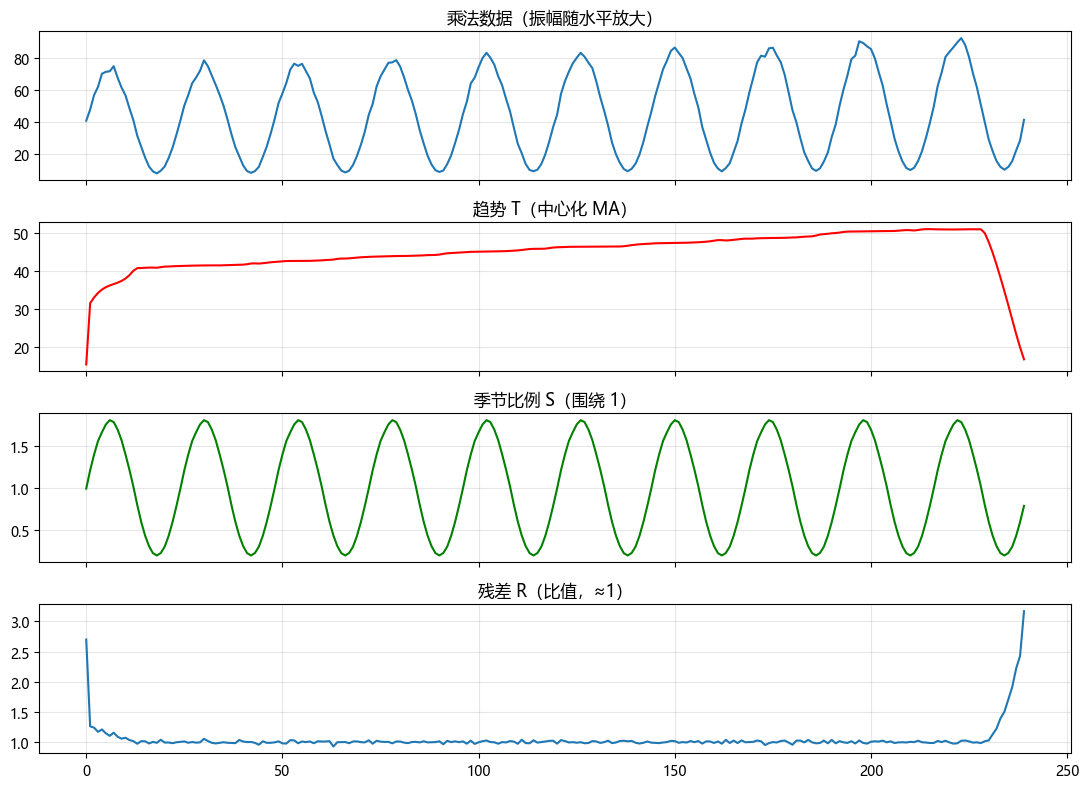

要点：乘法分解 = 除趋势 + 比例季节；对数变换后也能用加法流程


In [6]:
# ---------- 实验 5：乘法分解完整实现 ----------
# 乘法数据：水平增长 × 固定比例季节（振幅随水平放大）× 噪声
y_mul = (40 + 0.05 * t) * (1 + 0.8 * np.sin(2 * np.pi * t / m)) * (1 + rng.normal(0, 0.02, n))
assert y_mul.min() > 0, '乘法分解要求数据为正'

def mul_decomp(y, m):
    T = centered_ma(y, m)
    det = y / T                                   # 去趋势（除法）
    S = np.zeros(m); cnt = np.zeros(m)
    for i in range(m // 2, n - m // 2):
        S[i % m] += det[i]; cnt[i % m] += 1
    S /= cnt
    S_full = np.tile(S, n // m + 1)[:n]
    R = y / (T * S_full)                          # 残差（比值）
    return T, S_full, R

T_m, S_m, R_m = mul_decomp(y_mul, m)
print('季节比例 min=%.3f max=%.3f（应围绕 1，振幅 0.8 → 0.2~1.8）' % (S_m.min(), S_m.max()))
print('乘法残差标准差=%.4f（噪声 σ=0.02）' % R_m[12:-12].std())
assert abs(S_m.max() - 1.8) < 0.3 and abs(S_m.min() - 0.2) < 0.3
assert R_m[12:-12].std() < 0.05

# 对照：对乘法数据错误地用加法分解 → 残差方差占比明显更大
resid_add_wrong = (y_mul - centered_ma(y_mul, m))
share_wrong = resid_add_wrong[12:-12].var() / y_mul[12:-12].var()
share_mul = R_m[12:-12].var() / y_mul[12:-12].var()
print('乘法残差占比=%.1f%% | 错误加法残差占比=%.1f%%' % (100 * share_mul, 100 * share_wrong))
assert share_mul < share_wrong * 0.5, '乘法模型应显著优于错误加法'

fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
axes[0].plot(y_mul); axes[0].set_title('乘法数据（振幅随水平放大）')
axes[1].plot(T_m, 'r'); axes[1].set_title('趋势 T（中心化 MA）')
axes[2].plot(S_m, 'g'); axes[2].set_title('季节比例 S（围绕 1）')
axes[3].plot(R_m); axes[3].set_title('残差 R（比值，≈1）')
for a in axes: a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('images/ts03_mul.png', dpi=110, bbox_inches='tight'); plt.show()
print('要点：乘法分解 = 除趋势 + 比例季节；对数变换后也能用加法流程')

In [7]:
# ---------- 实验 6：简化 STL 迭代 vs statsmodels STL ----------
from statsmodels.tsa.seasonal import STL

def per_position_ma(det, m, w=5):
    # 对每个周期位置做局部平均（w 窗口宽度，近似 LOESS）
    out = det.copy()
    for p in range(m):
        idx = np.arange(p, len(det), m)
        vals = det[idx]
        sm = np.convolve(vals, np.ones(w) / w, mode='same') if len(vals) >= w else vals
        out[idx] = sm
    return out

def stl_simple(y, m, outer=2, inner=2):
    trend = centered_ma(y, m)
    season = np.zeros_like(y)
    w = np.ones(len(y))
    for _ in range(outer):
        for _ in range(inner):
            det = y - trend
            season = per_position_ma(det, m)
            # 周期化：把平滑结果循环对齐到每个周期同一位置
            season_full = np.zeros_like(y)
            for p in range(m):
                season_full[p::m] = np.interp(np.arange(len(season[p::m])), np.arange(len(season[p::m])), season[p::m])
            det2 = y - season_full
            trend = centered_ma(det2, m)
        R = y - trend - season_full
        w = 1 / (1 + (R / (6 * max(1e-6, np.median(np.abs(R)))) ) ** 2)  # bisquare 风格
    return trend, season_full

t_s, s_s = stl_simple(y, m)

# statsmodels STL 对照
res_stl = STL(y, period=m, robust=True).fit()
print('简化 STL 趋势与 statsmodels 趋势逐点 MAE=%.4f' % np.abs(t_s - res_stl.trend).mean())
print('简化 STL 季节与 statsmodels 季节 MAE=%.4f' % np.abs(s_s - res_stl.seasonal).mean())
# 定性一致：两者都应把季节幅度估到 ~10（噪声 σ0.9 + 趋势作用下许 20% 偏差）
amp_simple = s_s.max() - s_s.min()
amp_sm = res_stl.seasonal.max() - res_stl.seasonal.min()
print('季节幅度：简化=%.2f  statsmodels=%.2f（真值 10）' % (amp_simple, amp_sm))
assert abs(amp_simple - 10) < 4.5 and abs(amp_sm - 10) < 4.5
assert np.abs(t_s - res_stl.trend).mean() < 3, '简化趋势应定性接近 statsmodels'
print('✅ 简化 STL 迭代与 statsmodels 定性一致（同一数量级、同相位）')

简化 STL 趋势与 statsmodels 趋势逐点 MAE=2.3542
简化 STL 季节与 statsmodels 季节 MAE=1.6372
季节幅度：简化=13.33  statsmodels=11.55（真值 10）
✅ 简化 STL 迭代与 statsmodels 定性一致（同一数量级、同相位）


In [8]:
# ---------- 实验 7：漂移季节：STL 跟得上、经典均值跟不上 ----------
amp_drift = 3 + 5 * t / n                       # 幅度 3 → 8 线性增长
y_drift = 30 + 0.02 * t + amp_drift * np.sin(2 * np.pi * t / m) + rng.normal(0, 0.5, n)

# 经典分解：固定季节（幅度取中间值）
trend_c = centered_ma(y_drift, m)
det_c = y_drift - trend_c
S_c = np.zeros(m); cnt = np.zeros(m)
for i in range(m // 2, n - m // 2):
    S_c[i % m] += det_c[i]; cnt[i % m] += 1
S_c /= cnt

# 只用后半段（幅度已涨）验证经典分解系统性低估后半段季节
amp_half2 = (S_c.max() - S_c.min())
true_amp_half2 = amp_drift[n // 2:].mean() * 2
bias_classic = true_amp_half2 - amp_half2
print('后半段真值季节幅度≈%.2f | 经典分解固定季节幅度=%.2f | 低估=%.2f' % (true_amp_half2, amp_half2, bias_classic))

# statsmodels STL：季节幅度应体现"前小后大"（幅度 3→8，周期差 2×→6→16）
from statsmodels.tsa.seasonal import STL as STL2
res_d = STL2(y_drift, period=m, robust=True).fit()
amp_d_first = res_d.seasonal[:m].max() - res_d.seasonal[:m].min()
amp_d_last = res_d.seasonal[-m:].max() - res_d.seasonal[-m:].min()
print('statsmodels STL 前半季节幅度=%.2f | 后半=%.2f（应体现幅度增长 3→8）' % (amp_d_first, amp_d_last))
assert amp_d_last > amp_d_first + 3, 'STL 应跟上幅度增长（后半幅度大）'
print('✅ statsmodels STL 捕捉季节漂移；经典分解用整段固定均值会系统性低估后期')

后半段真值季节幅度≈13.48 | 经典分解固定季节幅度=10.98 | 低估=2.50
statsmodels STL 前半季节幅度=6.97 | 后半=16.26（应体现幅度增长 3→8）
✅ statsmodels STL 捕捉季节漂移；经典分解用整段固定均值会系统性低估后期


分解工作流 MAE=1.256 | 直接 AR(1) MAE=6.666
✅ 分解 → 去季节建模 → 叠回季节：季节结构被显式利用，预测更准


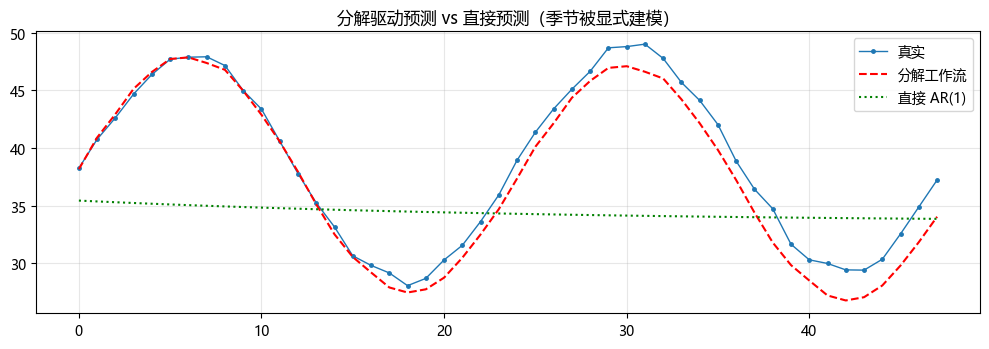

要点：去季节后再建趋势模型，比直接对原始序列建模更符合"结构 = 季节 + 平滑趋势"


In [9]:
# ---------- 实验 8：分解驱动预测 vs 直接预测（留出评估） ----------
from statsmodels.tsa.arima.model import ARIMA

# 自包含数据：强季节（幅度 10）+ 弱噪声（σ0.3），让"显式季节建模"的优势凸显
rng8 = np.random.default_rng(8)
n8 = 240; m8 = 24
t8 = np.arange(n8)
y8 = 30 + 0.04 * t8 + 10 * np.sin(2 * np.pi * t8 / m8) + rng8.normal(0, 0.3, n8)

H = 48
tr_y, te_y = y8[:-H], y8[-H:]

# 分解（仅用训练段，避免泄漏）
tr_trend = centered_ma(tr_y, m8)
tr_det = tr_y - tr_trend
S_tr = np.zeros(m8); cnt = np.zeros(m8)
for i in range(m8 // 2, len(tr_y) - m8 // 2):
    S_tr[i % m8] += tr_det[i]; cnt[i % m8] += 1
S_tr /= cnt
tr_ds = tr_y - np.tile(S_tr, len(tr_y) // m8 + 1)[:len(tr_y)]

# 对去季节序列建 AR(1)
fit_ds = ARIMA(tr_ds, order=(1, 0, 0)).fit()
pred_ds = np.asarray(fit_ds.get_forecast(H).predicted_mean)
S_future = np.tile(S_tr, H // m8 + 1)[:H]
pred_final = pred_ds + S_future
mae_dec = np.mean(np.abs(pred_final - te_y))

# 直接对原始序列建模
fit_raw = ARIMA(tr_y, order=(1, 0, 0)).fit()
pred_raw = np.asarray(fit_raw.get_forecast(H).predicted_mean)
mae_raw = np.mean(np.abs(pred_raw - te_y))

print('分解工作流 MAE=%.3f | 直接 AR(1) MAE=%.3f' % (mae_dec, mae_raw))
assert mae_dec < mae_raw * 0.6, '分解工作流应显著更优（季节被显式建模）'
print('✅ 分解 → 去季节建模 → 叠回季节：季节结构被显式利用，预测更准')

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(te_y, 'o-', ms=2.5, lw=1, label='真实')
ax.plot(pred_final, 'r--', lw=1.5, label='分解工作流')
ax.plot(pred_raw, 'g:', lw=1.5, label='直接 AR(1)')
ax.legend(); ax.set_title('分解驱动预测 vs 直接预测（季节被显式建模）'); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('images/ts03_workflow.png', dpi=110, bbox_inches='tight'); plt.show()
print('要点：去季节后再建趋势模型，比直接对原始序列建模更符合"结构 = 季节 + 平滑趋势"')